In [7]:
import sys, time
from pathlib import Path
from collections import Counter
import polars as pl

sys.path.append('..')
from src.config import load_config
cfg = load_config()

PROC = Path('..') / 'data' / 'processed'
REPORTS = Path('..') / 'reports'
REPORTS.mkdir(exist_ok=True)

F = pl.scan_parquet(PROC / 'features.parquet')
META = ['case_id', 'date_decision', 'MONTH', 'WEEK_NUM', 'target', 'split']
SCH = F.collect_schema()
FEATS = [c for c in SCH if c not in META]

def source(c):
    return c.split('__')[0] if '__' in c else 'depth0'

TR = F.filter(pl.col('split') == 'train')
print(f'{len(FEATS)} feature')
print(dict(Counter(source(c) for c in FEATS).most_common()))

726 feature
{'depth0': 210, 'credit_bureau_a_1': 164, 'credit_bureau_b_1': 91, 'applprev_1': 76, 'person_2': 43, 'person_1': 36, 'applprev_2': 25, 'credit_bureau_a_2': 24, 'credit_bureau_b_2': 13, 'debitcard_1': 12, 'deposit_1': 8, 'tax_registry_b_1': 7, 'tax_registry_c_1': 7, 'tax_registry_a_1': 5, 'other_1': 5}


In [8]:
t0 = time.time()
n_tr = TR.select(pl.len()).collect().item()
miss = TR.select([pl.col(c).null_count() for c in FEATS]).collect().row(0, named=True)
nuni = TR.select([pl.col(c).drop_nulls().n_unique() for c in FEATS]).collect().row(0, named=True)

prof = pl.DataFrame({
    'feature': FEATS,
    'source': [source(c) for c in FEATS],
    'dtype': [str(SCH[c]) for c in FEATS],
    'miss': [miss[c] / n_tr for c in FEATS],
    'n_unique': [nuni[c] for c in FEATS],
})

pl.Config(tbl_rows=30, tbl_cols=-1, tbl_width_chars=200)
print(f'Train: {n_tr:,} hồ sơ ({time.time()-t0:.0f}s)\n')

# Tổng hợp theo bảng nguồn
print(prof.group_by('source').agg(
    n=pl.len(),
    miss_median=pl.col('miss').median().round(3),
    gt95=(pl.col('miss') > 0.95).sum(),
    gt99=(pl.col('miss') > 0.99).sum(),
    toan_null=(pl.col('miss') == 1).sum(),
    hang_so=(pl.col('n_unique') <= 1).sum(),
).sort('n', descending=True))

# Phân bố tỷ lệ missing của toàn bộ feature
bins = [(-0.01, 0, '0%'), (0, 0.5, '(0, 50%]'), (0.5, 0.9, '(50, 90%]'), (0.9, 0.95, '(90, 95%]'),
        (0.95, 0.99, '(95, 99%]'), (0.99, 0.999999, '(99, 100%)'), (0.999999, 1, '100%')]
print('\nPhân bố tỷ lệ missing:')
for lo, hi, lab in bins:
    print(f'  {lab:>11}: {prof.filter((pl.col("miss") > lo) & (pl.col("miss") <= hi)).height}')

prof.write_csv(REPORTS / 'eda_train_profile.csv')
print('\nĐã lưu', REPORTS / 'eda_train_profile.csv')

Train: 841,500 hồ sơ (6s)

shape: (15, 7)
┌───────────────────┬─────┬─────────────┬──────┬──────┬───────────┬─────────┐
│ source            ┆ n   ┆ miss_median ┆ gt95 ┆ gt99 ┆ toan_null ┆ hang_so │
│ ---               ┆ --- ┆ ---         ┆ ---  ┆ ---  ┆ ---       ┆ ---     │
│ str               ┆ u32 ┆ f64         ┆ u32  ┆ u32  ┆ u32       ┆ u32     │
╞═══════════════════╪═════╪═════════════╪══════╪══════╪═══════════╪═════════╡
│ depth0            ┆ 210 ┆ 0.323       ┆ 40   ┆ 14   ┆ 7         ┆ 23      │
│ credit_bureau_a_1 ┆ 164 ┆ 0.439       ┆ 8    ┆ 2    ┆ 2         ┆ 2       │
│ credit_bureau_b_1 ┆ 91  ┆ 0.982       ┆ 91   ┆ 10   ┆ 0         ┆ 3       │
│ applprev_1        ┆ 76  ┆ 0.248       ┆ 0    ┆ 0    ┆ 0         ┆ 1       │
│ person_2          ┆ 43  ┆ 0.013       ┆ 2    ┆ 2    ┆ 0         ┆ 1       │
│ person_1          ┆ 36  ┆ 0.261       ┆ 11   ┆ 11   ┆ 7         ┆ 14      │
│ applprev_2        ┆ 25  ┆ 0.23        ┆ 0    ┆ 0    ┆ 0         ┆ 0       │
│ credit_bureau_a_2 ┆ 

In [9]:
t0 = time.time()
SPLITS = ['train', 'valid', 'calib', 'oot1', 'oot2']

ms = (F.group_by('split')
       .agg([pl.len().alias('__n')] + [pl.col(c).null_count().alias(c) for c in FEATS])
       .collect())
mw = (ms.with_columns(pl.col('split').cast(pl.String))
        .unpivot(index=['split', '__n'], variable_name='feature', value_name='n_null')
        .with_columns(miss=pl.col('n_null') / pl.col('__n'))
        .pivot(on='split', index='feature', values='miss')
        .select(['feature'] + SPLITS)
        .join(prof.select('feature', 'source'), on='feature')
        .with_columns(d_oot1=pl.col('oot1') - pl.col('train'),
                      d_oot2=pl.col('oot2') - pl.col('train')))
print(f'({time.time()-t0:.0f}s)\n')

# Missing trung vị theo bảng nguồn và theo tập
print(mw.group_by('source')
        .agg([pl.col(s).median().round(3) for s in SPLITS])
        .sort('source'))

# Các feature toàn null trên Train: ở các tập sau có dữ liệu không
allnull = prof.filter(pl.col('miss') == 1)['feature'].to_list()
print(f'\n{len(allnull)} feature toàn null trên Train — missing ở các tập khác:')
print(mw.filter(pl.col('feature').is_in(allnull)).select(['feature'] + SPLITS).sort('oot2'))

# Feature có mức sẵn có thay đổi > 20 điểm phần trăm giữa Train và OOT
flag = mw.filter(((pl.col('d_oot1').abs() > 0.2) | (pl.col('d_oot2').abs() > 0.2))
                 & ~pl.col('feature').is_in(allnull))
print(f'\n{flag.height} feature (ngoài nhóm toàn null) có missing lệch > 20 điểm % giữa Train và OOT:')
print(flag.group_by('source').agg(n=pl.len(),
                                  d_oot1_tb=pl.col('d_oot1').mean().round(3),
                                  d_oot2_tb=pl.col('d_oot2').mean().round(3)).sort('n', descending=True))

mw.write_csv(REPORTS / 'eda_missing_by_split.csv')
print('\nĐã lưu', REPORTS / 'eda_missing_by_split.csv')

(2s)

shape: (15, 6)
┌───────────────────┬───────┬───────┬───────┬───────┬───────┐
│ source            ┆ train ┆ valid ┆ calib ┆ oot1  ┆ oot2  │
│ ---               ┆ ---   ┆ ---   ┆ ---   ┆ ---   ┆ ---   │
│ str               ┆ f64   ┆ f64   ┆ f64   ┆ f64   ┆ f64   │
╞═══════════════════╪═══════╪═══════╪═══════╪═══════╪═══════╡
│ applprev_1        ┆ 0.248 ┆ 0.246 ┆ 0.244 ┆ 0.17  ┆ 0.164 │
│ applprev_2        ┆ 0.23  ┆ 0.225 ┆ 0.222 ┆ 0.153 ┆ 0.149 │
│ credit_bureau_a_1 ┆ 0.439 ┆ 0.169 ┆ 0.181 ┆ 0.125 ┆ 0.156 │
│ credit_bureau_a_2 ┆ 0.504 ┆ 0.168 ┆ 0.18  ┆ 0.134 ┆ 0.156 │
│ credit_bureau_b_1 ┆ 0.982 ┆ 0.97  ┆ 0.973 ┆ 0.973 ┆ 0.964 │
│ credit_bureau_b_2 ┆ 0.982 ┆ 0.97  ┆ 0.973 ┆ 0.973 ┆ 0.964 │
│ debitcard_1       ┆ 0.993 ┆ 0.994 ┆ 0.995 ┆ 0.992 ┆ 0.992 │
│ deposit_1         ┆ 0.932 ┆ 0.941 ┆ 0.943 ┆ 0.925 ┆ 0.92  │
│ depth0            ┆ 0.323 ┆ 0.315 ┆ 0.317 ┆ 0.242 ┆ 0.227 │
│ other_1           ┆ 1.0   ┆ 1.0   ┆ 0.968 ┆ 0.876 ┆ 0.87  │
│ person_1          ┆ 0.261 ┆ 0.246 ┆ 0.246 ┆ 0.2

{'applprev_1': 'applprev_1__count', 'credit_bureau_a_1': 'credit_bureau_a_1__count', 'credit_bureau_b_1': 'credit_bureau_b_1__count', 'tax_registry_a_1': 'tax_registry_a_1__count', 'tax_registry_b_1': 'tax_registry_b_1__count', 'tax_registry_c_1': 'tax_registry_c_1__count', 'debitcard_1': 'debitcard_1__count', 'deposit_1': 'deposit_1__count', 'person_1': 'person_1__app__birth_259D', 'other_1': 'other_1__amtdebitincoming_4809443A', 'applprev_2': 'applprev_2__count', 'person_2': 'person_2__count', 'credit_bureau_b_2': 'credit_bureau_b_2__count', 'credit_bureau_a_2': 'credit_bureau_a_2__pmts_year_1139T__n_months'}
shape: (14, 5)
┌───────────────────┬──────────┬───────────┬─────────┬─────────┐
│ source            ┆ tuan_dau ┆ tuan_cuoi ┆ phu_min ┆ phu_max │
│ ---               ┆ ---      ┆ ---       ┆ ---     ┆ ---     │
│ str               ┆ i64      ┆ i64       ┆ f64     ┆ f64     │
╞═══════════════════╪══════════╪═══════════╪═════════╪═════════╡
│ applprev_1        ┆ 0        ┆ 91      

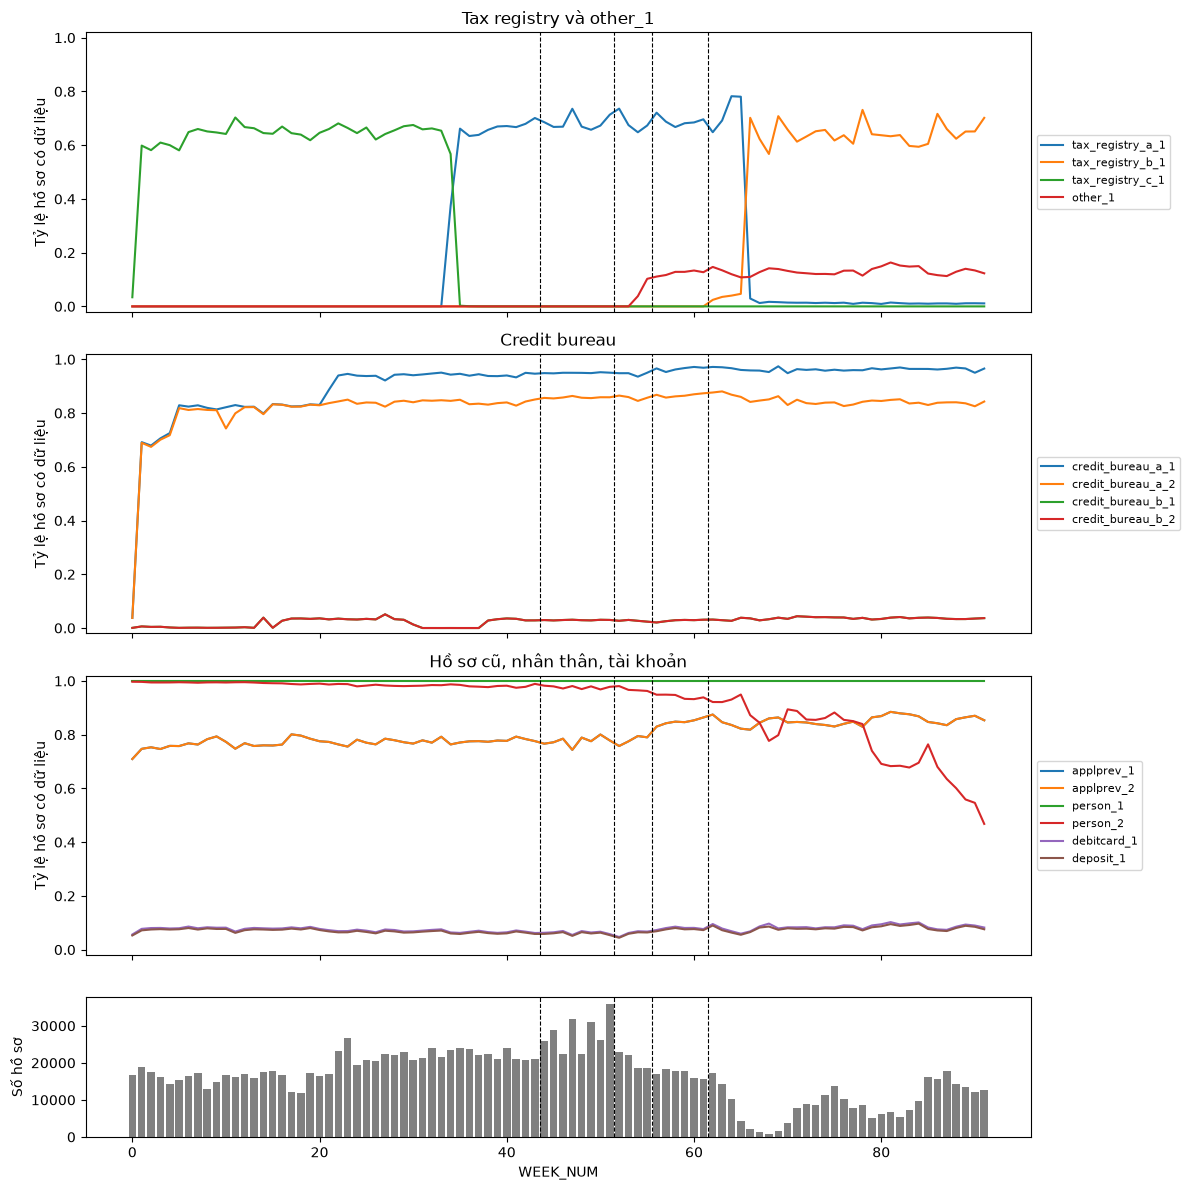

In [10]:
import matplotlib.pyplot as plt

FIG = REPORTS / 'figures'
FIG.mkdir(exist_ok=True)

# Mỗi bảng chọn một cột đại diện để đo độ phủ: <bảng>__count nếu có, nếu không lấy cột đầu tiên
srcs = [s for s in dict.fromkeys(prof['source'].to_list()) if s != 'depth0']
REP = {s: (f'{s}__count' if f'{s}__count' in SCH else next(c for c in FEATS if source(c) == s)) for s in srcs}
print(REP)

cov = (F.group_by('WEEK_NUM')
        .agg([pl.len().alias('n')] + [pl.col(c).is_not_null().mean().alias(s) for s, c in REP.items()])
        .sort('WEEK_NUM').collect())

# Tuần đầu và tuần cuối mà mỗi bảng có dữ liệu (độ phủ > 1%)
rows = []
for s in REP:
    w = cov.filter(pl.col(s) > 0.01)['WEEK_NUM']
    rows.append({'source': s, 'tuan_dau': w.min(), 'tuan_cuoi': w.max(),
                 'phu_min': round(cov[s].min(), 3), 'phu_max': round(cov[s].max(), 3)})
print(pl.DataFrame(rows))

groups = {
    'Tax registry và other_1': ['tax_registry_a_1', 'tax_registry_b_1', 'tax_registry_c_1', 'other_1'],
    'Credit bureau': ['credit_bureau_a_1', 'credit_bureau_a_2', 'credit_bureau_b_1', 'credit_bureau_b_2'],
    'Hồ sơ cũ, nhân thân, tài khoản': ['applprev_1', 'applprev_2', 'person_1', 'person_2', 'debitcard_1', 'deposit_1'],
}
wk = cov['WEEK_NUM'].to_list()
fig, axes = plt.subplots(4, 1, figsize=(12, 12), sharex=True,
                         gridspec_kw={'height_ratios': [3, 3, 3, 1.5]})
for ax, (title, ss) in zip(axes, groups.items()):
    for s in ss:
        if s in cov.columns:
            ax.plot(wk, cov[s].to_list(), label=s, lw=1.5)
    ax.set_title(title)
    ax.set_ylabel('Tỷ lệ hồ sơ có dữ liệu')
    ax.set_ylim(-0.02, 1.02)
    ax.legend(fontsize=8, loc='center left', bbox_to_anchor=(1, 0.5))
axes[3].bar(wk, cov['n'].to_list(), color='grey')
axes[3].set_ylabel('Số hồ sơ')
axes[3].set_xlabel('WEEK_NUM')
for ax in axes:
    for b in [44, 52, 56, 62]:                      # ranh giới Train | Valid | Calib | OOT-1 | OOT-2
        ax.axvline(b - 0.5, color='k', ls='--', lw=0.8)
fig.tight_layout()
fig.savefig(FIG / 'eda_coverage_by_week.png', dpi=150, bbox_inches='tight')
plt.show()

In [11]:
# Các feature của 3 bảng thuế trong depth1
TAX = {s: [c for c in FEATS if source(c) == s]
       for s in ['tax_registry_c_1', 'tax_registry_a_1', 'tax_registry_b_1']}
for s, cs in TAX.items():
    print(s, [c.split('__', 1)[1] for c in cs])

# (1) Phân vị của từng feature số, tính trên các hồ sơ có dữ liệu của nguồn đó
rows = []
for s, cs in TAX.items():
    num = [c for c in cs if SCH[c].is_numeric()]
    r = (F.filter(pl.col(f'{s}__count').is_not_null())
          .select([pl.len().alias('n')] + [e for c in num for e in (
              pl.col(c).quantile(0.1).alias(f'{c}|p10'),
              pl.col(c).median().alias(f'{c}|p50'),
              pl.col(c).quantile(0.9).alias(f'{c}|p90'))])
          .collect().row(0, named=True))
    for c in num:
        rows.append({'source': s, 'feature': c.split('__', 1)[1], 'n': r['n'],
                     'p10': r[f'{c}|p10'], 'p50': r[f'{c}|p50'], 'p90': r[f'{c}|p90']})
print(pl.DataFrame(rows))

# (2) Default rate: có / không có dữ liệu thuế — CHỈ trong Train
WIN_TR = {'tax_registry_c_1': (1, 33), 'tax_registry_a_1': (34, 43)}
for s, (a, b) in WIN_TR.items():
    print(f'\n{s}, tuần {a}–{b} (Train):')
    print(F.filter(pl.col('WEEK_NUM').is_between(a, b))
           .group_by(pl.col(f'{s}__count').is_not_null().alias('co_du_lieu_thue'))
           .agg(n=pl.len(), default_rate=pl.col('target').mean())
           .sort('co_du_lieu_thue').collect())

tax_registry_c_1 ['count', 'employername_160M__nuniq', 'pmtamount_36A__max', 'pmtamount_36A__mean', 'pmtamount_36A__sum', 'processingdate_168D__min', 'processingdate_168D__max']
tax_registry_a_1 ['count', 'amount_4527230A__max', 'amount_4527230A__mean', 'amount_4527230A__sum', 'name_4527232M__nuniq']
tax_registry_b_1 ['count', 'amount_4917619A__max', 'amount_4917619A__mean', 'amount_4917619A__sum', 'deductiondate_4917603D__min', 'deductiondate_4917603D__max', 'name_4917606M__nuniq']
shape: (19, 6)
┌──────────────────┬─────────────────────────────┬────────┬─────────────┬──────────────┬──────────────┐
│ source           ┆ feature                     ┆ n      ┆ p10         ┆ p50          ┆ p90          │
│ ---              ┆ ---                         ┆ ---    ┆ ---         ┆ ---          ┆ ---          │
│ str              ┆ str                         ┆ i64    ┆ f64         ┆ f64          ┆ f64          │
╞══════════════════╪═════════════════════════════╪════════╪═════════════╪════════

shape: (1, 3)
┌────────┬────────┬────────┐
│ c_va_a ┆ a_va_b ┆ c_va_b │
│ ---    ┆ ---    ┆ ---    │
│ u32    ┆ u32    ┆ u32    │
╞════════╪════════╪════════╡
│ 7129   ┆ 4233   ┆ 0      │
└────────┴────────┴────────┘
Nhóm mới: ['tax__count', 'tax__employer_nuniq', 'tax__amount_max', 'tax__amount_mean', 'tax__amount_sum', 'tax__amount_max_to_mean']


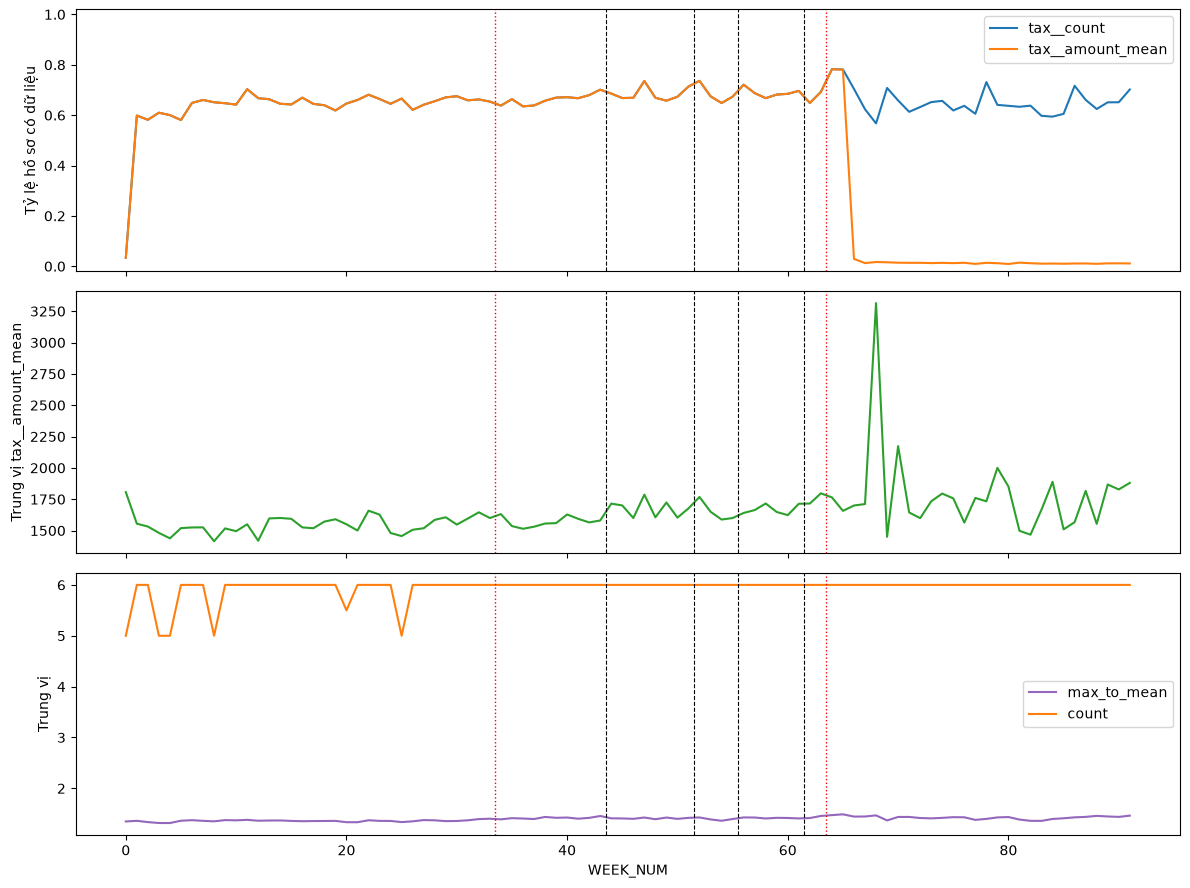

In [12]:
from src.features.unify_tax import unify_tax, TAX_SOURCES

# Hồ sơ có dữ liệu ở 2 nguồn cùng lúc
cnt = {s: pl.col(f'{s}__count').is_not_null() for s in TAX_SOURCES}
C_, A_, B_ = TAX_SOURCES
print(F.select(c_va_a=(cnt[C_] & cnt[A_]).sum(),
               a_va_b=(cnt[A_] & cnt[B_]).sum(),
               c_va_b=(cnt[C_] & cnt[B_]).sum()).collect())

U = unify_tax(F)
tax_cols = [c for c in U.collect_schema().names() if c.startswith('tax__')]
print('Nhóm mới:', tax_cols)

wkt = (U.group_by('WEEK_NUM')
        .agg(phu_count=pl.col('tax__count').is_not_null().mean(),
             phu_amount=pl.col('tax__amount_mean').is_not_null().mean(),
             med_count=pl.col('tax__count').median(),
             med_amount_mean=pl.col('tax__amount_mean').median(),
             med_max_to_mean=pl.col('tax__amount_max_to_mean').median())
        .sort('WEEK_NUM').collect())

w = wkt['WEEK_NUM'].to_list()
fig, axes = plt.subplots(3, 1, figsize=(12, 9), sharex=True)
axes[0].plot(w, wkt['phu_count'].to_list(), label='tax__count')
axes[0].plot(w, wkt['phu_amount'].to_list(), label='tax__amount_mean')
axes[0].set_ylabel('Tỷ lệ hồ sơ có dữ liệu'); axes[0].set_ylim(-0.02, 1.02); axes[0].legend()
axes[1].plot(w, wkt['med_amount_mean'].to_list(), color='tab:green')
axes[1].set_ylabel('Trung vị tax__amount_mean')
axes[2].plot(w, wkt['med_max_to_mean'].to_list(), color='tab:purple', label='max_to_mean')
axes[2].plot(w, wkt['med_count'].to_list(), color='tab:orange', label='count')
axes[2].set_ylabel('Trung vị'); axes[2].set_xlabel('WEEK_NUM'); axes[2].legend()
for ax in axes:
    for b in [34, 64]:
        ax.axvline(b - 0.5, color='red', ls=':', lw=1)          # tuần chuyển nguồn
    for b in [44, 52, 56, 62]:
        ax.axvline(b - 0.5, color='k', ls='--', lw=0.8)        # ranh giới tập
fig.tight_layout()
fig.savefig(FIG / 'eda_tax_unified_by_week.png', dpi=150, bbox_inches='tight')
plt.show()

In [13]:
t0 = time.time()
TRU = unify_tax(F).filter(pl.col('split') == 'train')
USCH = TRU.collect_schema()
UF = [c for c in USCH if c not in META]
NUM = [c for c in UF if USCH[c].is_numeric() or USCH[c] == pl.Boolean]
print(f'{len(UF)} feature sau khi gộp thuế; {len(NUM)} feature số/boolean được tính')

def uni_stats(df, c):
    d = df.select(c, 'target')
    nn = d.drop_nulls(c)
    na = d.filter(pl.col(c).is_null())
    row = {'feature': c, 'miss': na.height / d.height,
           'dr_co_gia_tri': nn['target'].mean() if nn.height else None,
           'dr_missing': na['target'].mean() if na.height else None, 'gini': None}
    p = nn['target'].sum()
    q = nn.height - p
    if p >= 50 and q >= 50 and nn[c].n_unique() >= 2:
        rk = nn[c].rank('average')
        auc = (rk.filter(nn['target'] == 1).sum() - p * (p + 1) / 2) / (p * q)
        row['gini'] = 2 * auc - 1
    return row

rows = []
for i in range(0, len(NUM), 60):
    cols = NUM[i:i + 60]
    df = TRU.select(['target'] + [pl.col(c).cast(pl.Float64) for c in cols]).collect()
    rows += [uni_stats(df, c) for c in cols]

uni = (pl.DataFrame(rows)
         .with_columns(source=pl.col('feature').map_elements(
             lambda c: 'tax' if c.startswith('tax__') else source(c), return_dtype=pl.String),
             abs_gini=pl.col('gini').abs())
         .sort('abs_gini', descending=True, nulls_last=True))
print(f'({time.time()-t0:.0f}s)\n')

print('Top 30 feature theo |Gini| đơn biến trên Train:')
print(uni.head(30).select('feature', 'source', 'miss', 'gini', 'dr_co_gia_tri', 'dr_missing'))

print('\nTheo bảng nguồn:')
print(uni.group_by('source').agg(
    n=pl.len(),
    max_abs_gini=pl.col('abs_gini').max().round(3),
    n_gini_gt_0_05=(pl.col('abs_gini') > 0.05).sum(),
    n_gini_gt_0_10=(pl.col('abs_gini') > 0.10).sum(),
).sort('max_abs_gini', descending=True))

print('\n|Gini| > 0.5 (nghi leakage):', uni.filter(pl.col('abs_gini') > 0.5)['feature'].to_list())

uni.write_csv(REPORTS / 'eda_univariate_train.csv')
print('Đã lưu', REPORTS / 'eda_univariate_train.csv')

713 feature sau khi gộp thuế; 666 feature số/boolean được tính
(17s)

Top 30 feature theo |Gini| đơn biến trên Train:
shape: (30, 6)
┌─────────────────────────────────┬───────────────────┬──────────┬───────────┬───────────────┬────────────┐
│ feature                         ┆ source            ┆ miss     ┆ gini      ┆ dr_co_gia_tri ┆ dr_missing │
│ ---                             ┆ ---               ┆ ---      ┆ ---       ┆ ---           ┆ ---        │
│ str                             ┆ str               ┆ f64      ┆ f64       ┆ f64           ┆ f64        │
╞═════════════════════════════════╪═══════════════════╪══════════╪═══════════╪═══════════════╪════════════╡
│ riskassesment_940T              ┆ depth0            ┆ 0.962949 ┆ -0.398351 ┆ 0.058278      ┆ 0.028658   │
│ credit_bureau_b_2__pmts_pmtsov… ┆ credit_bureau_b_2 ┆ 0.982455 ┆ 0.392107  ┆ 0.057302      ┆ 0.029263   │
│ credit_bureau_b_2__pmts_dpdval… ┆ credit_bureau_b_2 ┆ 0.982455 ┆ 0.38572   ┆ 0.057302      ┆ 0.029263   │
│ c

In [14]:
import numpy as np

t0 = time.time()
U_all = unify_tax(F)
EPS = 1e-4
PSI_LO, PSI_HI = 0.1, 0.25          # configs: monitoring.psi_thresholds

def psi(p, q):
    p, q = np.clip(p, EPS, None), np.clip(q, EPS, None)
    return float(np.sum((q - p) * np.log(q / p)))

rows = []
for i in range(0, len(NUM), 60):
    cols = NUM[i:i + 60]
    df = U_all.select(['split'] + [pl.col(c).cast(pl.Float64) for c in cols]).collect()
    sp = df['split'].cast(pl.String).to_numpy()
    masks = {s: sp == s for s in SPLITS}
    for c in cols:
        x = df[c].to_numpy()
        xt = x[masks['train']]
        xt = xt[~np.isnan(xt)]
        if xt.size == 0:
            continue
        edges = np.unique(np.quantile(xt, np.linspace(0.1, 0.9, 9)))   # mốc chia fit trên Train
        b = np.where(np.isnan(x), 0, np.searchsorted(edges, x, side='right') + 1)  # 0 = missing
        nb = edges.size + 2
        dist = lambda m: np.bincount(b[m], minlength=nb) / m.sum()
        pt = dist(masks['train'])
        rows.append({'feature': c, **{f'psi_{s}': psi(pt, dist(masks[s])) for s in SPLITS[1:]}})

stab = pl.DataFrame(rows).join(uni.select('feature', 'source', 'miss', 'gini', 'abs_gini'), on='feature')
print(f'{stab.height} feature ({time.time()-t0:.0f}s)\n')

print('Số feature theo mức PSI:')
for s in SPLITS[1:]:
    v = stab[f'psi_{s}']
    print(f'  {s:>5}: < {PSI_LO}: {(v < PSI_LO).sum():>3} | {PSI_LO}–{PSI_HI}: '
          f'{((v >= PSI_LO) & (v < PSI_HI)).sum():>3} | > {PSI_HI}: {(v >= PSI_HI).sum():>3}')

print('\nPSI trung vị theo bảng nguồn:')
print(stab.group_by('source').agg([pl.col(f'psi_{s}').median().round(3) for s in SPLITS[1:]])
          .sort('psi_oot2', descending=True))

print('\nTop 30 theo |Gini| kèm PSI:')
print(stab.sort('abs_gini', descending=True).head(30)
          .select('feature', 'gini', 'miss', *[f'psi_{s}' for s in SPLITS[1:]]))

stab.write_csv(REPORTS / 'eda_psi.csv')
print('Đã lưu', REPORTS / 'eda_psi.csv')

653 feature (46s)

Số feature theo mức PSI:
  valid: < 0.1: 530 | 0.1–0.25:  29 | > 0.25:  94
  calib: < 0.1: 528 | 0.1–0.25:  31 | > 0.25:  94
   oot1: < 0.1: 483 | 0.1–0.25:  66 | > 0.25: 104
   oot2: < 0.1: 420 | 0.1–0.25:  79 | > 0.25: 154

PSI trung vị theo bảng nguồn:
shape: (12, 5)
┌───────────────────┬───────────┬───────────┬──────────┬──────────┐
│ source            ┆ psi_valid ┆ psi_calib ┆ psi_oot1 ┆ psi_oot2 │
│ ---               ┆ ---       ┆ ---       ┆ ---      ┆ ---      │
│ str               ┆ f64       ┆ f64       ┆ f64      ┆ f64      │
╞═══════════════════╪═══════════╪═══════════╪══════════╪══════════╡
│ person_2          ┆ 0.006     ┆ 0.016     ┆ 0.07     ┆ 0.738    │
│ tax               ┆ 0.031     ┆ 0.028     ┆ 0.039    ┆ 0.656    │
│ credit_bureau_a_2 ┆ 0.233     ┆ 0.223     ┆ 0.453    ┆ 0.308    │
│ credit_bureau_a_1 ┆ 0.096     ┆ 0.084     ┆ 0.16     ┆ 0.167    │
│ applprev_1        ┆ 0.005     ┆ 0.008     ┆ 0.056    ┆ 0.077    │
│ depth0            ┆ 0.005   

In [15]:
# (1) Top 30 đúng thứ tự
print('Top 30 theo |Gini| (đã sửa):')
print(stab.sort('abs_gini', descending=True, nulls_last=True).head(30)
          .select('feature', 'gini', 'miss', *[f'psi_{s}' for s in SPLITS[1:]]))

# (2) Feature có PSI Train→Valid > 0.25: thay đổi do missing hay do giá trị
hi = (stab.filter(pl.col('psi_valid') >= PSI_HI)
          .join(mw.select('feature', pl.col('train').alias('miss_train'), pl.col('valid').alias('miss_valid')),
                on='feature', how='left'))
print(f'\n{hi.height} feature có PSI Train→Valid > {PSI_HI}:')
print(hi.group_by('source').agg(
    n=pl.len(),
    miss_train_tb=pl.col('miss_train').mean().round(3),
    miss_valid_tb=pl.col('miss_valid').mean().round(3),
    psi_valid_tv=pl.col('psi_valid').median().round(3),
    abs_gini_tb=pl.col('abs_gini').mean().round(3),
).sort('n', descending=True))

# (3) PSI của Valid so với Train tuần 20–43 (mốc chia fit trên phần muộn của Train)
WK_CUT = 20
hi_cols = hi['feature'].to_list()
rows = []
for i in range(0, len(hi_cols), 60):
    cols = hi_cols[i:i + 60]
    df = U_all.select(['split', 'WEEK_NUM'] + [pl.col(c).cast(pl.Float64) for c in cols]).collect()
    sp, wk = df['split'].cast(pl.String).to_numpy(), df['WEEK_NUM'].to_numpy()
    m_late, m_val = (sp == 'train') & (wk >= WK_CUT), sp == 'valid'
    for c in cols:
        x = df[c].to_numpy()
        xt = x[m_late]
        xt = xt[~np.isnan(xt)]
        if xt.size == 0:
            continue
        edges = np.unique(np.quantile(xt, np.linspace(0.1, 0.9, 9)))
        b = np.where(np.isnan(x), 0, np.searchsorted(edges, x, side='right') + 1)
        nb = edges.size + 2
        dist = lambda m: np.bincount(b[m], minlength=nb) / m.sum()
        rows.append({'feature': c, 'psi_valid_vs_late': psi(dist(m_late), dist(m_val))})

hi = hi.join(pl.DataFrame(rows), on='feature', how='left')
v = hi['psi_valid_vs_late']
print(f'\nPSI Valid so với Train tuần {WK_CUT}–43 (cho {hi.height} feature trên):')
print(f'  < {PSI_LO}: {(v < PSI_LO).sum()} | {PSI_LO}–{PSI_HI}: {((v >= PSI_LO) & (v < PSI_HI)).sum()} | > {PSI_HI}: {(v >= PSI_HI).sum()}')
print(hi.group_by('source').agg(
    n=pl.len(),
    psi_valid_full=pl.col('psi_valid').median().round(3),
    psi_valid_late=pl.col('psi_valid_vs_late').median().round(3),
).sort('n', descending=True))

print('\nCác feature vẫn lệch lớn kể cả khi so với Train tuần 20–43:')
print(hi.filter(pl.col('psi_valid_vs_late') >= PSI_HI)
        .sort('abs_gini', descending=True, nulls_last=True)
        .select('feature', 'source', 'gini', 'miss_train', 'miss_valid', 'psi_valid', 'psi_valid_vs_late').head(20))

Top 30 theo |Gini| (đã sửa):
shape: (30, 7)
┌─────────────────────────────────┬───────────┬──────────┬───────────┬───────────┬──────────┬──────────┐
│ feature                         ┆ gini      ┆ miss     ┆ psi_valid ┆ psi_calib ┆ psi_oot1 ┆ psi_oot2 │
│ ---                             ┆ ---       ┆ ---      ┆ ---       ┆ ---       ┆ ---      ┆ ---      │
│ str                             ┆ f64       ┆ f64      ┆ f64       ┆ f64       ┆ f64      ┆ f64      │
╞═════════════════════════════════╪═══════════╪══════════╪═══════════╪═══════════╪══════════╪══════════╡
│ riskassesment_940T              ┆ -0.398351 ┆ 0.962949 ┆ 0.001631  ┆ 0.002426  ┆ 0.002375 ┆ 0.001007 │
│ credit_bureau_b_2__pmts_pmtsov… ┆ 0.392107  ┆ 0.982455 ┆ 0.006605  ┆ 0.004276  ┆ 0.004761 ┆ 0.013943 │
│ credit_bureau_b_2__pmts_dpdval… ┆ 0.38572   ┆ 0.982455 ┆ 0.006526  ┆ 0.004262  ┆ 0.004875 ┆ 0.013953 │
│ credit_bureau_b_1__overdueamou… ┆ 0.385594  ┆ 0.982441 ┆ 0.008926  ┆ 0.008799  ┆ 0.012219 ┆ 0.027447 │
│ credit_bu

In [16]:
import re
pl.Config(fmt_str_lengths=80, tbl_rows=60, tbl_width_chars=220)

# (a) 29 feature vẫn lệch, tên đầy đủ
still = hi.filter(pl.col('psi_valid_vs_late') >= PSI_HI)
print(still.sort('psi_valid_vs_late', descending=True)
           .select('feature', 'gini', 'miss_train', 'miss_valid', 'psi_valid_vs_late'))

# (b) Feature có tên chứa year/month: miền giá trị để nhận ra năm lịch tuyệt đối
cal = [c for c in UF
       if re.search(r'year|month', c.split('__')[1] if '__' in c else c, re.I)
       and (USCH[c].is_numeric())]
rng = U_all.select([e for c in cal for e in (
          pl.col(c).min().alias(f'{c}|min'), pl.col(c).max().alias(f'{c}|max'))]).collect().row(0, named=True)
cal_tbl = (pl.DataFrame([{'feature': c, 'min': float(rng[f'{c}|min'] or 0), 'max': float(rng[f'{c}|max'] or 0)}
                         for c in cal])
             .with_columns(nam_lich=(pl.col('min') >= 1990) & (pl.col('max') <= 2035))
             .sort('nam_lich', 'feature', descending=[True, False]))
print(f'\n{len(cal)} feature có year/month trong tên; {cal_tbl["nam_lich"].sum()} feature mang năm lịch tuyệt đối:')
print(cal_tbl)

# (c) Depth0 còn lệch: tuần bắt đầu / kết thúc có dữ liệu (độ phủ tuần > 5%)
d0_still = [c for c in still['feature'].to_list() if source(c) == 'depth0']
cw = (U_all.group_by('WEEK_NUM')
           .agg([pl.col(c).is_not_null().mean().alias(c) for c in d0_still])
           .sort('WEEK_NUM').collect())
rows = []
for c in d0_still:
    w = cw.filter(pl.col(c) > 0.05)['WEEK_NUM']
    rows.append({'feature': c, 'tuan_dau': w.min(), 'tuan_cuoi': w.max(),
                 'phu_tuan_20_43': round(cw.filter(pl.col('WEEK_NUM').is_between(20, 43))[c].mean(), 3),
                 'phu_valid': round(cw.filter(pl.col('WEEK_NUM').is_between(44, 51))[c].mean(), 3)})
print('\nDepth0 — khoảng tuần có dữ liệu:')
print(pl.DataFrame(rows).sort('tuan_dau'))

shape: (29, 5)
┌──────────────────────────────────────────────────────┬───────────┬────────────┬────────────┬───────────────────┐
│ feature                                              ┆ gini      ┆ miss_train ┆ miss_valid ┆ psi_valid_vs_late │
│ ---                                                  ┆ ---       ┆ ---        ┆ ---        ┆ ---               │
│ str                                                  ┆ f64       ┆ f64        ┆ f64        ┆ f64               │
╞══════════════════════════════════════════════════════╪═══════════╪════════════╪════════════╪═══════════════════╡
│ credit_bureau_a_2__pmts_year_1139T__min_m            ┆ 0.084714  ┆ 0.195099   ┆ 0.141983   ┆ 5.584581          │
│ pmtscount_423L                                       ┆ -0.148132 ┆ 0.319503   ┆ 1.0        ┆ 5.277632          │
│ pmtssum_45A                                          ┆ -0.176845 ┆ 0.319503   ┆ 1.0        ┆ 5.051458          │
│ birthdate_574D                                       ┆ 0.191934